In [62]:
import sys
sys.path.append('../../src')

In [63]:
import pandas as pd
import numpy
from energiapy.components.temporal_scale import TemporalScale
from energiapy.components.resource import Resource, VaryingResource, Scope
from energiapy.components.process import Process, VaryingProcess
from energiapy.components.material import Material
from energiapy.components.location import Location
from energiapy.components.network import Network
from energiapy.components.scenario import Scenario
from energiapy.components.transport import Transport
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.plot import plot_results, plot_scenario
from energiapy.plot.plot_results import CostY, CostX
from energiapy.model.solve import solve
from itertools import product
from energiapy.components.result import Result
from itertools import product
from matplotlib import rc
import matplotlib.pyplot as plt
from energiapy.model.solve import solve
from energiapy.plot.plot_results import CostY, CostX
from energiapy.components.location import Location
from energiapy.plot import plot_results, plot_scenario
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.model.bounds import CapacityBounds
from energiapy.utils.data_utils import get_data, make_henry_price_df, remove_outliers, load_results
from energiapy.conversion.photovoltaic import solar_power_output
from energiapy.conversion.windmill import wind_power_output
from energiapy.model.constraints.integer_cuts import constraint_block_integer_cut, constraint_block_integer_cut_min
from scipy import stats

In [64]:
# To solve the scheduling level problem for the motivating example of 3 forms of LNG production with varying GWP (resets every year), varying ERCOT power prices & NG prices (fluctuates every hour for the next 5 years)
# For optimal cost vs emission scenario (and varying weights for emission reduction , eg, for 10% reduction in emission, what is the best case scenario)

In [65]:
horizon = 1
scales = TemporalScale(discretization_list=[365,24])

#1,24

In [66]:
bigM = 10**8
smallM = 0.001

In [67]:
# elec_price_df = pd.read_excel(r'C:\Users\marcopdsousa\Documents\energiapy\AICHE\AICHE 2025 Data\Complete_ERCOT_Prices_RepresentativeDay.xlsx')
# elec_price_df.index


In [68]:
elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Hourly Prices Belgium.csv')
#elec_price_df = elec_price_df[elec_price_df['SettlementPoint'] == 'HB_HOUSTON']
elec_price_df = elec_price_df[['Price (EUR/MWhe)']].reset_index(drop = True)
elec_price_df = elec_price_df[:8760]
elec_price_df['Price (EUR/MWhe)'] = elec_price_df['Price (EUR/MWhe)'].clip(lower=0)
elec_price_df

,Price (EUR/MWhe)
0,0.01
1,0.00
2,0.00
3,0.00
4,0.00
...,...
8755,108.18
8756,100.26
8757,99.19
8758,82.73


In [69]:
# elec_price_df

In [70]:
# Formula verified

#for index in elec_price_df.index:
    #if index <= 20:
        #GWP_value = 112.23
    #elif index <= 70:
        #GWP_value = 99.99
    #elif index <= 72:
        #GWP_value = 92.84
    #else:
        #GWP_value = 83.82
    
    #print(f"Index: {index}, GWP_value: {GWP_value}")  # To check the values dynamically


In [71]:
# for index in elec_price_df.index:
#     if index <= 365:
#         GWP_value = 112.23
#     elif index >365 and index<= 730:
#         GWP_value = ((99.99*(index - 365))+(112.23*365))/(index)
#     elif index >730 and index<= 1095:
#         GWP_value = ((92.84*(index - 730))+(99.99*365)+(112.23*365))/index
#     elif index >1095 and index<= 1460:
#         GWP_value = ((87.76*(index - 1095))+(99.99*365)+(112.23*365)+(92.84*730))/index
#     else:
#         GWP_value= (83.82*((index - 1460))+(87.76*365)+(99.99*365)+(112.23*365)+(92.84*730))/index
#         # for 5 years

## True Fuel mix GWP

In [72]:
# # Fuel Mix GWP
# GWP_df = pd.read_excel(r'C:\Users\marcopdsousa\Documents\energiapy\AICHE\AICHE 2025 Data\GWP_FuelMix_Day1.xlsx')
# GWP_df.head()
# GWP_df.index

## Test GWP Mix


In [73]:
#The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
GWP_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Carbon Intensity Belgium.csv')
# NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
GWP_df = GWP_df[['Carbon intensity Full']]
GWP_df = GWP_df[:8760].reset_index(drop = True)
GWP_df

,Carbon intensity Full
0,94.01
1,96.43
2,97.57
3,95.23
4,95.28
...,...
8755,179.82
8756,171.85
8757,172.25
8758,168.09


In [74]:
GWP_value = GWP_df.max()[0]
elec_price = elec_price_df.max()[0]

C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_17188\2507232968.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  GWP_value = GWP_df.max()[0]
C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_17188\2507232968.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  elec_price = elec_price_df.max()[0]


In [75]:
# Outputs

CO2 = Resource(name='CO2 Vented from the process', basis='kg/hr',
               label='Carbon dioxide vented from the process', block='Resource', gwp = 1, sell=True, scope = Scope.ONE)

Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               label='Methane from the process', block='Resource', gwp = 112.23, sell=True, scope = Scope.ONE)

NGL = Resource(name='Natural Gas Liquids_in_extraction', basis='kg/hr', label='Natural Gas Liquids_in_extraction', block='Resource', sell=True)

ProducedWater = Resource(name='H2O vented from the process',
               basis='kg/hr', sell=True, label='Water vented from the process', block='Resource')

LNG = Resource(name='LNG', demand = True, basis='kg/hr', label='LNG', block='Resource')

Boil_off_LNG = Resource(name='Boil_off_LNG', sell=True, basis='kg/hr', label='Boil_off_LNG', block='Resource')

Heat_Energy = Resource(name='Heat_Energy', basis='MW', label='Heat_Energy', sell=True, block='Resource')

#Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               #label='Methane from the process', block='Resource', gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP], sell=True, scope = Scope.ONE)

# Inputs

Power = Resource(name='Power', basis='MW', label='Power generated')

GridPower = Resource(name='GridPower', basis='MW',
                     cons_max=bigM, label='Power bought', gwp= GWP_value, price =elec_price ,varying = [VaryingResource.DETERMINISTIC_PRICE, VaryingResource.DETERMINISTIC_GWP], scope = Scope.TWO)
# Grid Power GWP from average value of time-varying GWP

ResourceWater = Resource(name='H2O',
               basis='kg/hr', cons_max=bigM, label='Water', price = 0.002, block='Resource')

Proppant_Additive = Resource(name='Proppant_Additive', basis='kg/hr', label='Proppant_Additive', block='Resource', price= 0.975, cons_max=bigM)
# Reference Link: https://www.maximizemarketresearch.com/market-report/global-proppant-market/14899/?utm_source=chatgpt.com

Diesel = Resource(name='Diesel', basis='kg/hr', label='Diesel', block='Resource', price= 0.98, cons_max=bigM)
# Reference Link: https://businessanalytiq.com/procurementanalytics/index/diesel-price-index/

Cooling_Water_In_Liquifaction = Resource(name='Cooling_Water_In_Liquifaction', basis='kg/hr', label='Cooling_Water_In_Liquifaction', block='Resource', cons_max=bigM, price= 0.0572)
# Reference link: https://www.intratec.us/products/industry-economics-worldwide/utility/cooling-water-united-states

LNG =  Resource(name='LNG', demand=True, basis='kg/hr', label='LNG', block='Resource')

Glycol = Resource(name='Glycol', basis='kg/hr', label='Glycol', block='Resource', cons_max=bigM, price= 0.052)
# Reference link: https://businessanalytiq.com/procurementanalytics/index/ethylene-glycol-price-index/

MDEA = Resource(name='MDEA', basis='kg/hr', label='MDEA', block='Resource', cons_max=bigM)

In [76]:
print(elec_price_df.shape[0])

8760


In [77]:
# FU: 1 kg/hr of LNG
# 3 methane producing processes

Grid = Process(name='Grid', conversion={GridPower: -1, Power: 1}, prod_min=smallM, prod_max=bigM, label='Grid', basis='MW')

Conventional_NG = Process(name='Conventional_NG', conversion={Boil_off_LNG: 0.01, Power: -0.0028, ResourceWater: -0.5, Diesel: -0.000741382, Glycol: -0.000818111, MDEA: -0.012391658, Cooling_Water_In_Liquifaction: -1.75,
                                                              Methane: 0.00395, CO2: 0.966504505 , NGL: 0.3, Heat_Energy: 0.02, ProducedWater: 0.912, LNG: 1}, capex=0.17, fopex=1.5, vopex=1.5, prod_min=0.1, prod_max=bigM, label='Conventional LNG', basis='kg/hr')  

# https://shareholdersunite.com/the-ioc-files-useful-background-material/the-economics-of-lng/

ShaleGas = Process(name='ShaleGas', conversion={Boil_off_LNG: 0.01, Power: -0.003, ResourceWater: -0.92, Diesel: -0.002041766, Glycol: -0.01875, MDEA: -0.284, Cooling_Water_In_Liquifaction: -2.75,
                                                              Methane: 0.00895, CO2: 2.1, NGL: 1.9, Heat_Energy: 0.074, ProducedWater: 2.2205, LNG: 1}, capex=0.19, fopex=0.6, vopex=0.6, prod_min=0.1, prod_max=bigM, label='ShaleGas', basis='kg/hr')
# https://marcelluscoalition.org/wp-content/uploads/2012/07/The-Arithmetic-of-Shale-Gas.pdf

Coalbed = Process(name='Coalbed', conversion={Boil_off_LNG: 0.01, Power: -0.01, Diesel: -0.075, Glycol: -0.026539527, MDEA: -0.401985372, Cooling_Water_In_Liquifaction: -3.25,
                                                              Methane: 0.811, CO2: 5.823126126, NGL: 0.062761905, Heat_Energy: 0.002, ProducedWater: 6.2755, LNG: 1}, capex=0.205, fopex=2.24, vopex=1.17, prod_min=0.1, prod_max=bigM, label='CoalBed', basis='kg/hr')

# capacity needed? No

In [78]:
process_set = {Grid, Conventional_NG, ShaleGas, Coalbed}

In [79]:
# network scale level is 2, due to indexing issues. However, this shouldn't change the final output as capex is smallM. Fopex will be mentiond in hourly level
#{Methane:GWP_value, GridPower: GWP_df}

houston = Location(name='Houston', processes=process_set,  price_factor={GridPower: elec_price_df}, gwp_factor= {GridPower: GWP_df} , expenditure_scale_level=0,
                   scales=scales, label='Houston', demand_scale_level=0, price_scale_level=1, gwp_scale_level = 1)


In [80]:

scenario = Scenario(name='scenario_full', network=houston, scales=scales,  demand_scale_level=0, expenditure_scale_level=0,
                    purchase_scale_level = 1, scheduling_scale_level=1, network_scale_level=0, gwp_scale_level = 1, 
                    label='full_case', demand={houston: {LNG:2000}})

In [81]:
print("Contents of scenario.gwp_dict:", Location.gwp_factor)
#code not reading demand or gwp factor

Contents of scenario.gwp_dict: None


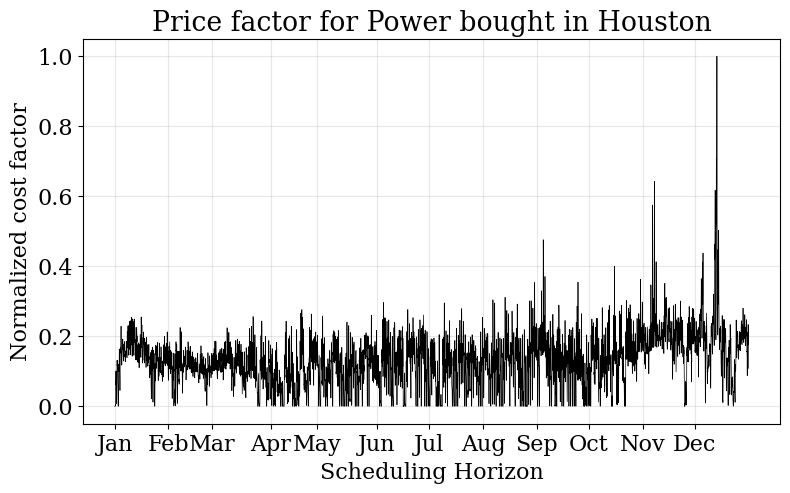

In [82]:
plot_scenario.price_factor(scenario=scenario, location=houston, resource=GridPower, fig_size=(9, 5), color='black')

In [83]:
#, Constraints.MODE

milp_cost = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost


In [84]:
from pyomo.environ import ConstraintList

# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons1.add(expr=milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Constraint 2: Ramp down
milp_cost.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons2.add(milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.05 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons3.add(expr=milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Constraint 2: Ramp down
milp_cost.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons4.add(milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.05 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons5.add(expr=milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Constraint 2: Ramp down
milp_cost.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0, 0, 0):
        milp_cost.cons6.add(milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.05 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])


In [85]:
# from pyomo.environ import ConstraintList

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons1 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons1.add(expr=milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons2 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons2.add(milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.05 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons3 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons3.add(expr=milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons4 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons4.add(milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.05 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons5 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons5.add(expr=milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons6 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0, 0, 0):
#         milp_cost.cons6.add(milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.05 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])


In [86]:
results_cost = solve(scenario=scenario, instance=milp_cost,
                     solver='gurobi', name=f"res_cost", print_solversteps=True, saveformat = '.pkl')

Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 609915 rows, 2949201 columns and 46255264 nonzeros
Model fingerprint: 0x963d4ace
Variable types: 2947741 continuous, 1460 integer (1460 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+03, 1e+08]
Presolve removed 164341 rows and 2565312 columns (presolve time = 5s)...
Presolve removed 333245 rows and 2734216 columns (presolve time = 10s)...
Presolve removed 501510 rows and 2902481 columns
Presolve time: 11.96s
Presolved: 108405 rows, 46720 columns, 259880 nonzeros
Variable types: 45260 continuous, 1460 integer (1460 

In [87]:
results_cost.output['objective']

733301.7216845549

In [88]:
results_cost.output['global_warming_potential_location']

{('Houston', 0): 2590902.5407807627,
 ('Houston', 1): 2590902.5407807627,
 ('Houston', 2): 2590902.5407807627,
 ('Houston', 3): 2590902.5407807627,
 ('Houston', 4): 2590902.5407807627,
 ('Houston', 5): 2590902.5407807627,
 ('Houston', 6): 2590902.5407807627,
 ('Houston', 7): 2590902.5407807627,
 ('Houston', 8): 2590902.5407807627,
 ('Houston', 9): 2590902.5407807627,
 ('Houston', 10): 2590902.5407807627,
 ('Houston', 11): 2590902.5407807627,
 ('Houston', 12): 2590902.5407807627,
 ('Houston', 13): 2590902.5407807627,
 ('Houston', 14): 2590902.5407807627,
 ('Houston', 15): 2590902.5407807627,
 ('Houston', 16): 2590902.5407807627,
 ('Houston', 17): 2590902.5407807627,
 ('Houston', 18): 2590902.5407807627,
 ('Houston', 19): 2590902.5407807627,
 ('Houston', 20): 2590902.5407807627,
 ('Houston', 21): 2590902.5407807627,
 ('Houston', 22): 2590902.5407807627,
 ('Houston', 23): 2590902.5407807627,
 ('Houston', 24): 2590902.5407807627,
 ('Houston', 25): 2590902.5407807627,
 ('Houston', 26): 2590

In [89]:
results_cost.output['Cap_P']

{('Houston', 'Coalbed', 0): 0.0,
 ('Houston', 'Coalbed', 1): 0.0,
 ('Houston', 'Coalbed', 2): 0.0,
 ('Houston', 'Coalbed', 3): 0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Coalbed', 5): 0.0,
 ('Houston', 'Coalbed', 6): 0.0,
 ('Houston', 'Coalbed', 7): 0.0,
 ('Houston', 'Coalbed', 8): 0.0,
 ('Houston', 'Coalbed', 9): 0.0,
 ('Houston', 'Coalbed', 10): 0.0,
 ('Houston', 'Coalbed', 11): 0.0,
 ('Houston', 'Coalbed', 12): 0.0,
 ('Houston', 'Coalbed', 13): 0.0,
 ('Houston', 'Coalbed', 14): 0.0,
 ('Houston', 'Coalbed', 15): 0.0,
 ('Houston', 'Coalbed', 16): 0.0,
 ('Houston', 'Coalbed', 17): 0.0,
 ('Houston', 'Coalbed', 18): 0.0,
 ('Houston', 'Coalbed', 19): 0.0,
 ('Houston', 'Coalbed', 20): 0.0,
 ('Houston', 'Coalbed', 21): 0.0,
 ('Houston', 'Coalbed', 22): 0.0,
 ('Houston', 'Coalbed', 23): 0.0,
 ('Houston', 'Coalbed', 24): 0.0,
 ('Houston', 'Coalbed', 25): 0.0,
 ('Houston', 'Coalbed', 26): 0.0,
 ('Houston', 'Coalbed', 27): 0.0,
 ('Houston', 'Coalbed', 28): 0.0,
 ('Houston', 'Coalbed', 

[89.47828708622251, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 89.47828708622252, 85.00437273191139, 80.75415409531581, 76.71644639055002, 72.88062407102251, 69.23659286747139, 66.47984033136066, 69.8038323479287, 73.29402396532514, 76.9587251635914, 80.80666142177097, 84.84699449285952, 89.0893442175025, 93.54381142837764, 98.22100199979653, 98.22100199979653, 98.22100199979653, 93.30995189980669, 88.64445430481635, 84.21223158957552, 80.00162001009674, 76.00153900959191, 72.20146205911232, 68.59138895615669, 65.16181950834886, 63.314133648914925, 66.47984033136068, 69.80383234792872, 73.29402396532515, 76.95872516359141, 80.80666142177098, 84.84699449285954, 89.08934421750251, 93.54381142837764, 98.22100199979653, 98.22100199979653, 103.13205209978636, 105.91201900539923, 105.91201900539923, 105.91201900539923, 105.91201

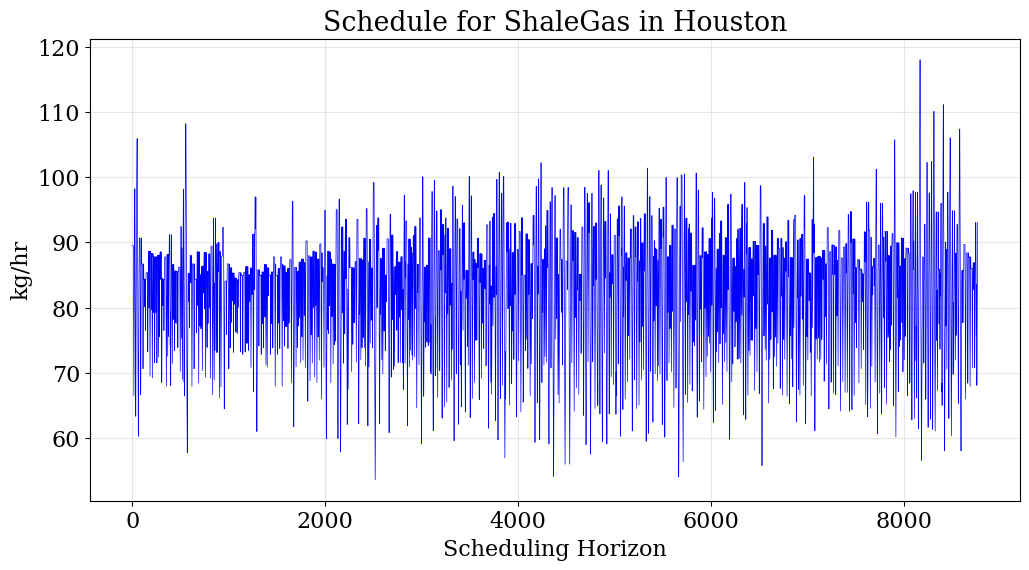

In [94]:
plot_results.schedule(results = results_cost, y_axis= 'P', component = 'ShaleGas', location='Houston')

In [53]:
# data = results_cost.output['P']
# df = pd.DataFrame(data,index=[0])
# df = df.T
# # Export the DataFrame to an Excel file
# df.to_excel(r'C:\Users\saatvisuresh_1\Desktop\Saatvi Thesis\5 year_final\P_output_F_both_Cost_min.xlsx', index=True)

In [54]:
#, Constraints.MODE

milp_gwp = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.MIN_GWP, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint demand
constraint network cost
objective gwp min


In [55]:
# P is production rate
# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons1.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *i] - milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons2.add(milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Conventional_NG', *i] <= 0.05*milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons3.add(expr = milp_gwp.P['Houston', 'ShaleGas', *i] - milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons4.add(milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'ShaleGas', *i] <= 0.05*milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Similarly:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons5.add(expr = milp_gwp.P['Houston', 'Coalbed', *i] - milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons6.add(milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Coalbed', *i] <= 0.05*milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])



In [56]:
results_gwp = solve(scenario=scenario, instance=milp_gwp,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 1668 rows, 8077 columns and 4423 nonzeros
Model fingerprint: 0x7571db7b
Coefficient statistics:
  Matrix range     [7e-04, 4e+02]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e-03, 1e+08]
Presolve removed 1523 rows and 8005 columns
Presolve time: 0.00s
Presolved: 145 rows, 72 columns, 544 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   6.250000e+01   0.000000e+00      0s
      26    4.4117095e+03   0.000000e+00   0.000000e+00      0s

Solved in 26 iterations and 0.00 seconds (0.00 work units)
Optimal objective  4.411709520e+03

In [57]:
results_gwp.output['objective']

4411.709520252732

In [58]:
results_gwp.output['Cost']

{None: 490503298.26217484}

In [59]:
# data = results_gwp.output['P']
# df = pd.DataFrame(data,index=[0])
# df = df.T
# # Export the DataFrame to an Excel file
# df.to_excel(r'C:\Users\saatvisuresh_1\Desktop\Saatvi Thesis\5 year_final\P_output_V_both_GWP_min.xlsx', index=True)

[63.87886879650191, 67.07281223632701, 70.42645284814337, 73.94777549055054, 77.64516426507807, 81.52742247833197, 85.60379360224857, 89.883983282361, 94.37818244647906, 99.09709156880301, 104.05194614724316, 109.25454345460533, 106.95676517552523, 101.60892691674897, 96.52848057091151, 91.70205654236594, 87.11695371524763, 82.76110602948525, 78.62305072801098, 74.69189819161043, 70.95730328202991, 67.40943811792842, 64.038966212032, 60.83701790143039]


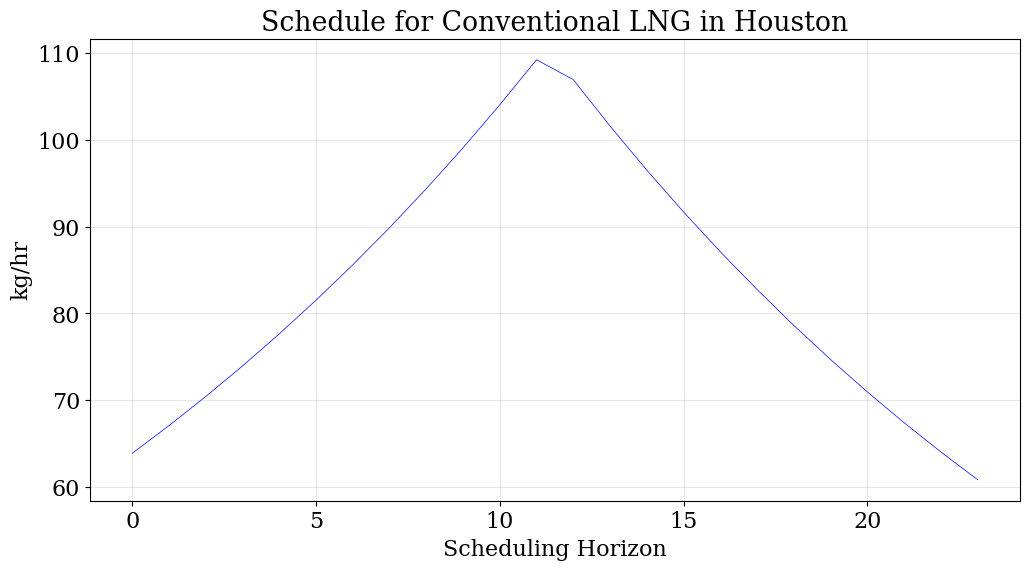

In [60]:
plot_results.schedule(results = results_gwp, y_axis= 'P', component = 'Conventional_NG', location='Houston')

In [ ]:
#X

5% emission reduction

In [ ]:
# Code 1
milp_gwp_5 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')
from src.energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
constraint_global_warming_potential_network_reduction(instance= milp_gwp_5, gwp_reduction_pct = 5, gwp = results_cost.output['global_warming_potential_network'][0])


In [ ]:
# Code 3 
results_gwp_5 = solve(scenario=scenario, instance=milp_gwp_5,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
# Code 4
results_gwp_5.output['objective']

In [ ]:
# Code 5
results_gwp_5.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_5.output['Cap_P']

In [ ]:
plot_results.schedule(results = results_gwp_5, y_axis= 'P', component = 'Conventional_NG', location='Houston')

In [ ]:
plot_results.schedule(results = results_gwp_5, y_axis= 'P', component = 'ShaleGas', location='Houston')

Emission Restrictions by 10%

In [ ]:
results_cost.output['global_warming_potential_network'][0]

In [ ]:
milp_gwp_10 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

from src.energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
constraint_global_warming_potential_network_reduction(instance= milp_gwp_10, gwp_reduction_pct = 10, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# P is production rate
# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_10.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons1.add(expr = milp_gwp_10.P['Houston', 'Conventional_NG', *i] - milp_gwp_10.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_10.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_10.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons2.add(milp_gwp_10.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_10.P['Houston', 'Conventional_NG', *i] <= 0.05*milp_gwp_10.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_10.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons3.add(expr = milp_gwp_10.P['Houston', 'ShaleGas', *i] - milp_gwp_10.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_10.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_10.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons4.add(milp_gwp_10.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_10.P['Houston', 'ShaleGas', *i] <= 0.05*milp_gwp_10.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Similarly:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_10.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons5.add(expr = milp_gwp_10.P['Houston', 'Coalbed', *i] - milp_gwp_10.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_10.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_10.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_10.cons6.add(milp_gwp_10.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_10.P['Houston', 'Coalbed', *i] <= 0.05*milp_gwp_10.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

In [ ]:
results_gwp_10 = solve(scenario=scenario, instance=milp_gwp_10,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
results_gwp_10.output['objective']

In [ ]:
results_gwp_10.output['global_warming_potential_location']

In [ ]:
results_gwp_10.output['Cap_P']

15% emission restrictions

In [ ]:
# Code 1
milp_gwp_15 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_15, gwp_reduction_pct = 15, gwp = results_cost.output['global_warming_potential_network'][0])

# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_15.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons1.add(
            expr = milp_gwp_15.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_15.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_15.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_15.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons2.add(
            milp_gwp_15.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_15.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_15.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_15.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons3.add(
            expr = milp_gwp_15.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_15.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_15.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_15.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons4.add(
            milp_gwp_15.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_15.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_15.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_15.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons5.add(
            expr = milp_gwp_15.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_15.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_15.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_15.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_15.cons6.add(
            milp_gwp_15.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_15.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_15.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

In [ ]:
# Code 3 
results_gwp_15 = solve(scenario=scenario, instance=milp_gwp_15,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
# Code 4
results_gwp_15.output['objective']

In [ ]:
# Code 5
results_gwp_15.output['global_warming_potential_location']

In [ ]:
results_gwp_15.output['Cap_P']

20% Emission Restrictions

In [ ]:
milp_gwp_20 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_20, gwp_reduction_pct = 20, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# P is production rate
# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_20.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons1.add(expr = milp_gwp_20.P['Houston', 'Conventional_NG', *i] - milp_gwp_20.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_20.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_20.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons2.add(milp_gwp_20.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_20.P['Houston', 'Conventional_NG', *i] <= 0.05*milp_gwp_20.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_20.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons3.add(expr = milp_gwp_20.P['Houston', 'ShaleGas', *i] - milp_gwp_20.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_20.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_20.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons4.add(milp_gwp_20.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_20.P['Houston', 'ShaleGas', *i] <= 0.05*milp_gwp_20.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Similarly:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_20.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons5.add(expr = milp_gwp_20.P['Houston', 'Coalbed', *i] - milp_gwp_20.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_20.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_20.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_20.cons6.add(milp_gwp_20.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_20.P['Houston', 'Coalbed', *i] <= 0.05*milp_gwp_20.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])



In [ ]:
results_gwp_20 = solve(scenario=scenario, instance=milp_gwp_20,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
results_gwp_20.output['objective']

In [ ]:
results_gwp_20.output['global_warming_potential_location']

In [ ]:
results_gwp_20.output['Cap_P']

25% emission reductions

In [ ]:
#Code 1
milp_gwp_25 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_25, gwp_reduction_pct = 25, gwp = results_cost.output['global_warming_potential_network'][0])

# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_25.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons1.add(
            expr = milp_gwp_25.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_25.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_25.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_25.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons2.add(
            milp_gwp_25.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_25.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_25.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_25.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons3.add(
            expr = milp_gwp_25.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_25.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_25.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_25.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons4.add(
            milp_gwp_25.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_25.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_25.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_25.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons5.add(
            expr = milp_gwp_25.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_25.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_25.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_25.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_25.cons6.add(
            milp_gwp_25.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_25.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_25.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_25 = solve(scenario=scenario, instance=milp_gwp_25,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
# Code 4
results_gwp_25.output['objective']

In [ ]:
# Code 5
results_gwp_25.output['global_warming_potential_location']

In [ ]:
results_gwp_25.output['Cap_P']

30% emission restrictions

In [ ]:
milp_gwp_30 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_30, gwp_reduction_pct = 30, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# P is production rate
# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_30.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons1.add(expr = milp_gwp_30.P['Houston', 'Conventional_NG', *i] - milp_gwp_30.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_30.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_30.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons2.add(milp_gwp_30.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_30.P['Houston', 'Conventional_NG', *i] <= 0.05*milp_gwp_30.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_30.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons3.add(expr = milp_gwp_30.P['Houston', 'ShaleGas', *i] - milp_gwp_30.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_30.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_30.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons4.add(milp_gwp_30.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_30.P['Houston', 'ShaleGas', *i] <= 0.05*milp_gwp_30.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

# Similarly:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp_30.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons5.add(expr = milp_gwp_30.P['Houston', 'Coalbed', *i] - milp_gwp_30.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05* milp_gwp_30.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

#Constraint 2: Ramp down

milp_gwp_30.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_30.cons6.add(milp_gwp_30.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp_30.P['Houston', 'Coalbed', *i] <= 0.05*milp_gwp_30.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]])

In [ ]:
results_gwp_30 = solve(scenario=scenario, instance=milp_gwp_30,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
results_gwp_30.output['objective']

In [ ]:
results_gwp_30.output['global_warming_potential_location']

In [ ]:
results_gwp_30.output['Cap_P']

35% emission constraint

In [ ]:
# Code 1
milp_gwp_35 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_35, gwp_reduction_pct = 35, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_35.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons1.add(
            expr = milp_gwp_35.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_35.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_35.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_35.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons2.add(
            milp_gwp_35.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_35.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_35.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_35.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons3.add(
            expr = milp_gwp_35.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_35.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_35.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_35.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons4.add(
            milp_gwp_35.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_35.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_35.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_35.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons5.add(
            expr = milp_gwp_35.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_35.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_35.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_35.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_35.cons6.add(
            milp_gwp_35.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_35.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_35.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_35 = solve(scenario=scenario, instance=milp_gwp_35,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
plot_results.schedule(results = results_gwp_35, y_axis= 'P', component = 'Conventional_NG', location='Houston')

In [ ]:
# Code 4
results_gwp_35.output['objective']

In [ ]:
# Code 5
results_gwp_35.output['global_warming_potential_location']

In [ ]:
# Code 5
results_gwp_35.output['Cap_P']

37% Emission reduction

In [ ]:
# Code 1
milp_gwp_37 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_37, gwp_reduction_pct = 37, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_37.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons1.add(
            expr = milp_gwp_37.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_37.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_37.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_37.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons2.add(
            milp_gwp_37.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_37.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_37.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_37.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons3.add(
            expr = milp_gwp_37.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_37.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_37.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_37.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons4.add(
            milp_gwp_37.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_37.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_37.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_37.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons5.add(
            expr = milp_gwp_37.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_37.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_37.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_37.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_37.cons6.add(
            milp_gwp_37.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_37.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_37.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_37 = solve(scenario=scenario, instance=milp_gwp_37,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
# Code 4
results_gwp_37.output['objective']


In [ ]:
# Code 5
results_gwp_37.output['global_warming_potential_location']

In [ ]:
results_gwp_37.output['Cap_P']

38% emission reduction

In [ ]:
# Code 1
milp_gwp_38 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_38, gwp_reduction_pct = 38, gwp = results_cost.output['global_warming_potential_network'][0])


In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_38.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons1.add(
            expr = milp_gwp_38.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_38.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_38.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_38.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons2.add(
            milp_gwp_38.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_38.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_38.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_38.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons3.add(
            expr = milp_gwp_38.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_38.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_38.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_38.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons4.add(
            milp_gwp_38.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_38.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_38.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_38.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons5.add(
            expr = milp_gwp_38.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_38.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_38.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_38.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_38.cons6.add(
            milp_gwp_38.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_38.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_38.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_38 = solve(scenario=scenario, instance=milp_gwp_38,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
# Code 4
results_gwp_38.output['objective']

In [ ]:
# Code 5
results_gwp_38.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_38.output['Cap_P']


39% emission reduction

In [ ]:
# Code 1
milp_gwp_39 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_39, gwp_reduction_pct = 39, gwp = results_cost.output['global_warming_potential_network'][0])


In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_39.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons1.add(
            expr = milp_gwp_39.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_39.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_39.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_39.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons2.add(
            milp_gwp_39.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_39.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_39.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_39.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons3.add(
            expr = milp_gwp_39.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_39.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_39.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_39.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons4.add(
            milp_gwp_39.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_39.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_39.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_39.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons5.add(
            expr = milp_gwp_39.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_39.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_39.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_39.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_39.cons6.add(
            milp_gwp_39.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_39.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_39.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_39 = solve(scenario=scenario, instance=milp_gwp_39,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
# Code 4
results_gwp_39.output['objective']


In [ ]:
# Code 5
results_gwp_39.output['global_warming_potential_location']


In [ ]:
# Code 6
results_gwp_39.output['Cap_P']

40% emission reduction

In [ ]:
# Code 1
milp_gwp_40 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_40, gwp_reduction_pct = 40, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_40.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons1.add(
            expr = milp_gwp_40.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_40.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_40.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_40.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons2.add(
            milp_gwp_40.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_40.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_40.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_40.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons3.add(
            expr = milp_gwp_40.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_40.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_40.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_40.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons4.add(
            milp_gwp_40.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_40.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_40.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_40.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons5.add(
            expr = milp_gwp_40.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_40.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_40.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_40.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_40.cons6.add(
            milp_gwp_40.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_40.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_40.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_40 = solve(scenario=scenario, instance=milp_gwp_40,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
# Code 4
results_gwp_40.output['objective']

In [ ]:
# Code 5
results_gwp_40.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_40.output['Cap_P']

41% emission reduction

In [ ]:
# Code 1
milp_gwp_41 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_41, gwp_reduction_pct = 41, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_41.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons1.add(
            expr = milp_gwp_41.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_41.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_41.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_41.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons2.add(
            milp_gwp_41.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_41.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_41.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_41.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons3.add(
            expr = milp_gwp_41.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_41.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_41.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_41.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons4.add(
            milp_gwp_41.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_41.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_41.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_41.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons5.add(
            expr = milp_gwp_41.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_41.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_41.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_41.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_41.cons6.add(
            milp_gwp_41.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_41.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_41.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

In [ ]:
# Code 3 
results_gwp_41 = solve(scenario=scenario, instance=milp_gwp_41,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


In [ ]:
results_gwp_41.output['objective']

In [ ]:
# Code 5
results_gwp_41.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_41.output['Cap_P']

42% emission reduction

In [ ]:
# Code 1
milp_gwp_42 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_42, gwp_reduction_pct = 42, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_42.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons1.add(
            expr = milp_gwp_42.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_42.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_42.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_42.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons2.add(
            milp_gwp_42.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_42.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_42.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_42.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons3.add(
            expr = milp_gwp_42.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_42.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_42.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_42.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons4.add(
            milp_gwp_42.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_42.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_42.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_42.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons5.add(
            expr = milp_gwp_42.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_42.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_42.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_42.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_42.cons6.add(
            milp_gwp_42.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_42.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_42.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

In [ ]:
# Code 3 
results_gwp_42 = solve(scenario=scenario, instance=milp_gwp_42,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
# Code 4
results_gwp_42.output['objective']

In [ ]:
# Code 5
results_gwp_42.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_42.output['Cap_P']

43% emission reduction

In [ ]:
# Code 1
milp_gwp_43 = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
                     Constraints.RESOURCE_BALANCE, Constraints.NETWORK, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint_global_warming_potential_network_reduction(instance= milp_gwp_43, gwp_reduction_pct = 43, gwp = results_cost.output['global_warming_potential_network'][0])

In [ ]:
# Code 2
from pyomo.environ import ConstraintList

# Constraint 1: Ramp-up for Conventional_NG
milp_gwp_43.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons1.add(
            expr = milp_gwp_43.P['Houston', 'Conventional_NG', *i] - 
                   milp_gwp_43.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_43.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 2: Ramp-down for Conventional_NG
milp_gwp_43.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons2.add(
            milp_gwp_43.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_43.P['Houston', 'Conventional_NG', *i] 
            <= 0.05 * milp_gwp_43.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 3: Ramp-up for ShaleGas
milp_gwp_43.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons3.add(
            expr = milp_gwp_43.P['Houston', 'ShaleGas', *i] - 
                   milp_gwp_43.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_43.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 4: Ramp-down for ShaleGas
milp_gwp_43.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons4.add(
            milp_gwp_43.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_43.P['Houston', 'ShaleGas', *i] 
            <= 0.05 * milp_gwp_43.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 5: Ramp-up for Coalbed
milp_gwp_43.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons5.add(
            expr = milp_gwp_43.P['Houston', 'Coalbed', *i] - 
                   milp_gwp_43.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] 
                   <= 0.05 * milp_gwp_43.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )

# Constraint 6: Ramp-down for Coalbed
milp_gwp_43.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp_43.cons6.add(
            milp_gwp_43.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - 
            milp_gwp_43.P['Houston', 'Coalbed', *i] 
            <= 0.05 * milp_gwp_43.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]]
        )


In [ ]:
# Code 3 
results_gwp_43 = solve(scenario=scenario, instance=milp_gwp_43,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')

In [ ]:
# Code 4
results_gwp_43.output['objective']

In [ ]:
# Code 5
results_gwp_43.output['global_warming_potential_location']

In [ ]:
# Code 6
results_gwp_43.output['Cap_P']